# Análise estrutural: congress-Twitter (G24)

## Verificar ambiente

In [1]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\lucas\OneDrive\Área de Trabalho\analise-snap\.venv\Scripts\python.exe
3.11.5 (tags/v3.11.5:cce6ba9, Aug 24 2023, 14:38:34) [MSC v.1936 64 bit (AMD64)]


## Carregar grafo

In [2]:
import networkx as nx

caminho = "dados/congress_network/congress.edgelist"
G = nx.read_edgelist(caminho, create_using=nx.DiGraph, nodetype=int)  # grafo dirigido
G_nd = G.to_undirected()  # grafo não dirigido

print(f"Vértices: {G_nd.number_of_nodes()}, arestas (não dirigido): {G_nd.number_of_edges()}")

Vértices: 475, arestas (não dirigido): 10222


## Small World

### comprimento médio e clusterização do grafo

In [3]:
L = nx.average_shortest_path_length(G_nd)
C = nx.average_clustering(G_nd)

print(f"Grafo: L = {L:.4f}, C = {C:.4f}")

Grafo: L = 2.0639, C = 0.3014


### grafos aleatórios cujas médias das medidas serão comparadas com o grafo

In [4]:
import statistics

n = G_nd.number_of_nodes()
m = G_nd.number_of_edges()

L_aleatorios, C_aleatorios = [], []
for seed in range(30):
    A = nx.gnm_random_graph(n, m, seed=seed)
    L_aleatorios.append(nx.average_shortest_path_length(A))
    C_aleatorios.append(nx.average_clustering(A))

L_random = sum(L_aleatorios) / len(L_aleatorios)
C_random = sum(C_aleatorios) / len(C_aleatorios)

print(f"Aleatório (média de 30): L = {L_random:.4f}, C = {C_random:.4f}")



print(f"Variação dos aleatórios: L entre {min(L_aleatorios):.4f} e {max(L_aleatorios):.4f}, C entre {min(C_aleatorios):.4f} e {max(C_aleatorios):.4f}")
print(f"Desvio padrão: L = {statistics.stdev(L_aleatorios):.4f}, C = {statistics.stdev(C_aleatorios):.4f}")

Aleatório (média de 30): L = 1.9272, C = 0.0908
Variação dos aleatórios: L entre 1.9264 e 1.9287, C entre 0.0890 e 0.0924
Desvio padrão: L = 0.0006, C = 0.0007


### comparação

In [5]:
razao_L = L / L_random
razao_C = C / C_random
sigma = razao_C / razao_L

print(f"L / L_random = {razao_L:.4f}")
print(f"C / C_random = {razao_C:.4f}")
print(f"Sigma = {sigma:.4f}")

L / L_random = 1.0709
C / C_random = 3.3200
Sigma = 3.1001


## Lei de potência

### graus do grafo

In [6]:
from collections import Counter
import numpy as np

graus = [d for _, d in G_nd.degree()]
n = len(graus)

contagem = Counter(graus)
k = np.array(sorted(contagem))
P_k = np.array([contagem[x] / n for x in k])

print(f"Grau mínimo: {min(graus)}, máximo: {max(graus)}, médio: {np.mean(graus):.4f}, mediana: {np.median(graus):.0f}")
print(f"Valores distintos de grau: {len(k)}")

Grau mínimo: 2, máximo: 214, médio: 43.0400, mediana: 38
Valores distintos de grau: 101


### Visualização dos graus

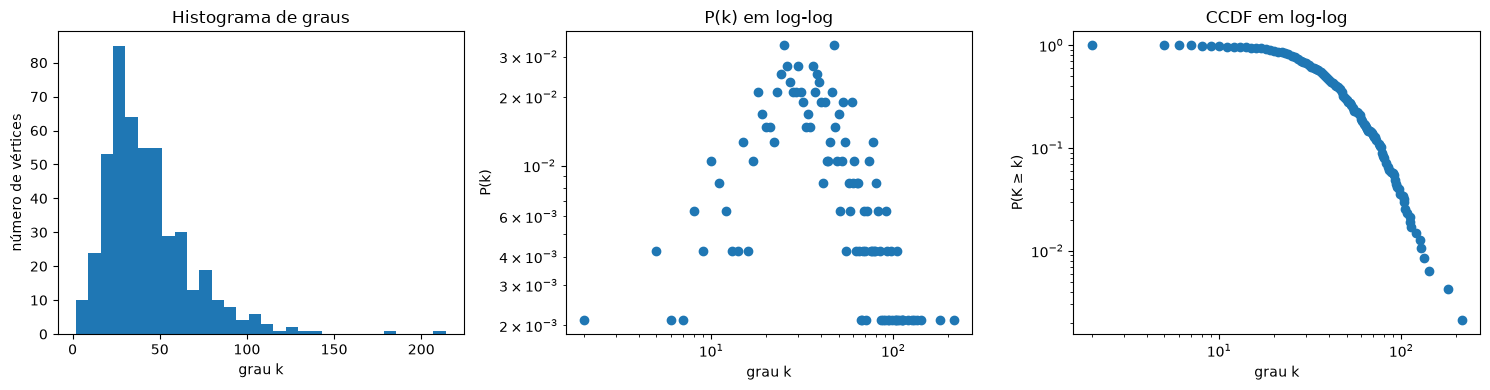

In [7]:
import matplotlib.pyplot as plt

graus_arr = np.array(graus)
ccdf = np.array([(graus_arr >= x).mean() for x in k])

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

ax1.hist(graus, bins=30)
ax1.set_title("Histograma de graus")
ax1.set_xlabel("grau k")
ax1.set_ylabel("número de vértices")

ax2.loglog(k, P_k, "o")
ax2.set_title("P(k) em log-log")
ax2.set_xlabel("grau k")
ax2.set_ylabel("P(k)")

ax3.loglog(k, ccdf, "o")
ax3.set_title("CCDF em log-log")
ax3.set_xlabel("grau k")
ax3.set_ylabel("P(K ≥ k)")

plt.tight_layout()
plt.show()

### ajuste log-log

γ = 2.4919
R² = 0.7388


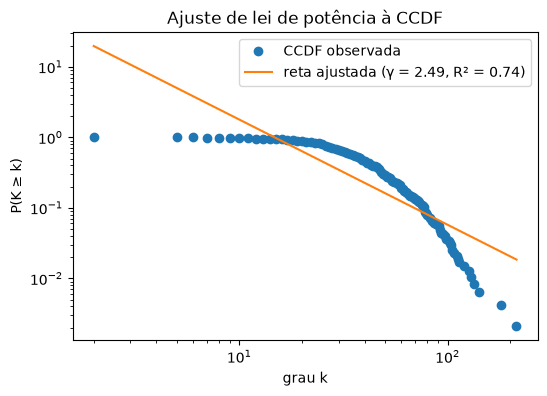

In [8]:
log_k = np.log10(k)
log_ccdf = np.log10(ccdf)

inclinacao, intercepto = np.polyfit(log_k, log_ccdf, 1)
previsto = inclinacao * log_k + intercepto
r2 = 1 - ((log_ccdf - previsto) ** 2).sum() / ((log_ccdf - log_ccdf.mean()) ** 2).sum()

print(f"γ = {1 - inclinacao:.4f}")
print(f"R² = {r2:.4f}")

plt.figure(figsize=(6, 4))
plt.loglog(k, ccdf, "o", label="CCDF observada")
plt.loglog(k, 10 ** previsto, "-", label=f"reta ajustada (γ = {1 - inclinacao:.2f}, R² = {r2:.2f})")
plt.xlabel("grau k")
plt.ylabel("P(K ≥ k)")
plt.title("Ajuste de lei de potência à CCDF")
plt.legend()
plt.show()

## Robustez: falha aleatória

### controle: grafo antes

In [9]:
#  grafo direcionado
import math
import random
import statistics

def medir(grafo):
    componentes = list(nx.strongly_connected_components(grafo))
    maior = max(componentes, key=len)
    total = grafo.number_of_nodes()
    a = len(maior) / total  # fração dos vértices na maior componente forte
    b = len(componentes)  # número de componentes fortes
    c = nx.average_shortest_path_length(grafo.subgraph(maior))  # distância média na maior componente
    d = sum(1 for v in grafo if grafo.degree(v) == 0) / total  # fração de vértices isolados
    return a, b, c, d

A_intacto, B_intacto, C_intacto, D_intacto = medir(G)

print(f"Maior componente (A) = {A_intacto:.4f}")
print(f"Nº de componentes (B) = {B_intacto}")
print(f"Distância média (C) = {C_intacto:.4f}")
print(f"Isolados (D) = {D_intacto:.4f}")

Maior componente (A) = 0.9874
Nº de componentes (B) = 7
Distância média (C) = 2.3549
Isolados (D) = 0.0000


### remove 5% dos vértices aleatoriamente 

In [10]:

T = 30  #repeticoes
r = math.ceil(0.05 * G.number_of_nodes())  # vértices removidos em cada repetição 

A_falha, B_falha, C_falha, D_falha = [], [], [], []
for seed in range(T):
    removidos = random.Random(seed).sample(list(G.nodes()), r)
    H = G.copy()
    H.remove_nodes_from(removidos)
    a, b, c, d = medir(H)
    A_falha.append(a)
    B_falha.append(b)
    C_falha.append(c)
    D_falha.append(d)

def resumo(nome, valores):
    print(f"{nome}: média = {statistics.mean(valores):.4f}, desvio padrão = {statistics.stdev(valores):.4f}")

print(f"Vértices removidos por repetição: {r}, repetições: {T}")
resumo("Maior componente (A)", A_falha)
resumo("Nº de componentes (B)", B_falha)
resumo("Distância média (C)", C_falha)
resumo("Isolados (D)", D_falha)

Vértices removidos por repetição: 24, repetições: 30
Maior componente (A): média = 0.9868, desvio padrão = 0.0015
Nº de componentes (B): média = 6.9667, desvio padrão = 0.6687
Distância média (C): média = 2.3689, desvio padrão = 0.0073
Isolados (D): média = 0.0000, desvio padrão = 0.0000


### Boxplots

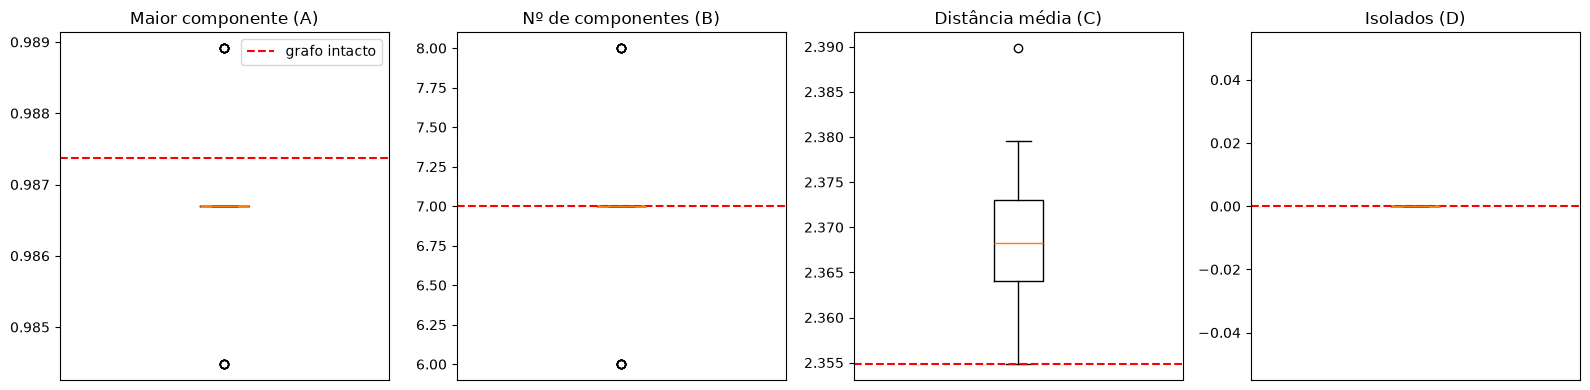

In [11]:
import matplotlib.pyplot as plt

titulos = ["Maior componente (A)", "Nº de componentes (B)", "Distância média (C)", "Isolados (D)"]
falha = [A_falha, B_falha, C_falha, D_falha]
intacto = [A_intacto, B_intacto, C_intacto, D_intacto]

fig, eixos = plt.subplots(1, 4, figsize=(16, 4))
for ax, titulo, valores, referencia in zip(eixos, titulos, falha, intacto):
    ax.boxplot(valores)
    ax.axhline(referencia, color="red", linestyle="--", label="grafo intacto")
    ax.set_title(titulo)
    ax.set_xticks([])
eixos[0].legend()
plt.tight_layout()
plt.show()

## Robustez: ataque direcionado

### ranking


In [12]:
#grafo direcionado

import json

with open("dados/congress_network/congress_network_data.json") as f:
    usernames = json.load(f)[0]["usernameList"]

intermediacao = nx.betweenness_centrality(G)
ranking = sorted(intermediacao, key=intermediacao.get, reverse=True)
mais_centrais = ranking[:r]

print(f"Vértices removidos: {r} (os 5% mais centrais)")
print("Os 5 primeiros do ranking:")
for v in ranking[:5]:
    print(f"  @{usernames[v]} (vértice {v}): intermediação = {intermediacao[v]:.4f}")
print(f"  + {r - 5} vértices")

Vértices removidos: 24 (os 5% mais centrais)
Os 5 primeiros do ranking:
  @GOPLeader (vértice 322): intermediação = 0.0730
  @SpeakerPelosi (vértice 367): intermediação = 0.0414
  @LeaderHoyer (vértice 254): intermediação = 0.0307
  @RepBobbyRush (vértice 393): intermediação = 0.0272
  @RepMMM (vértice 335): intermediação = 0.0178
  + 19 vértices


### remoção

In [13]:
H = G.copy()
H.remove_nodes_from(mais_centrais)
A_ataque, B_ataque, C_ataque, D_ataque = medir(H)

print(f"Maior componente (A) = {A_ataque:.4f}")
print(f"Nº de componentes (B) = {B_ataque}")
print(f"Distância média (C) = {C_ataque:.4f}")
print(f"Isolados (D) = {D_ataque:.4f}")

Maior componente (A) = 0.9867
Nº de componentes (B) = 7
Distância média (C) = 2.5215
Isolados (D) = 0.0000


### comparação com o boxplot

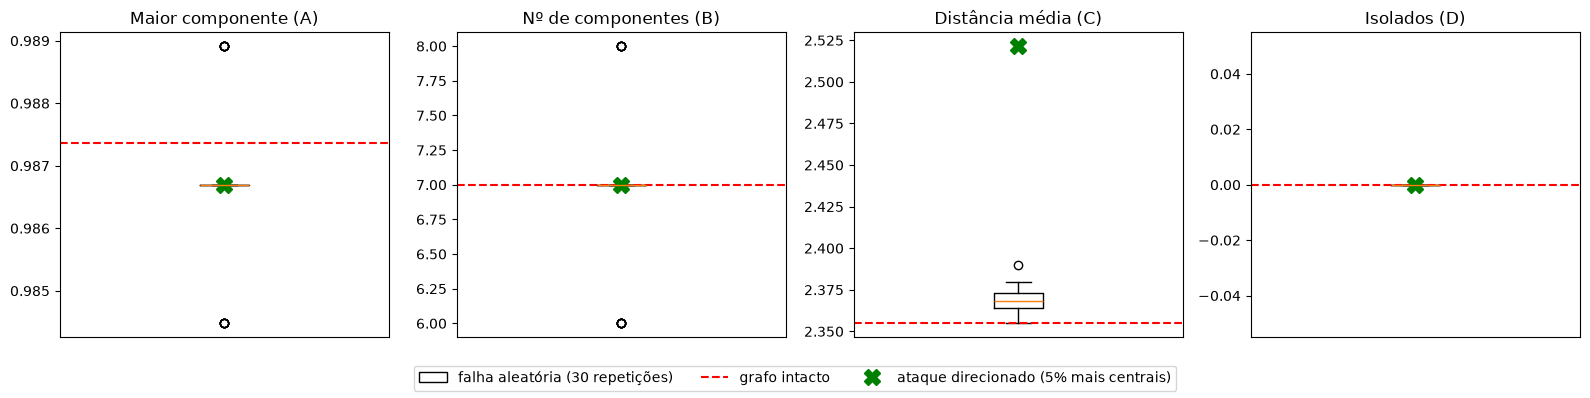

In [14]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

titulos = ["Maior componente (A)", "Nº de componentes (B)", "Distância média (C)", "Isolados (D)"]
falha = [A_falha, B_falha, C_falha, D_falha]
intacto = [A_intacto, B_intacto, C_intacto, D_intacto]
ataque = [A_ataque, B_ataque, C_ataque, D_ataque]

fig, eixos = plt.subplots(1, 4, figsize=(16, 4))
for ax, titulo, valores, referencia, atacado in zip(eixos, titulos, falha, intacto, ataque):
    ax.boxplot(valores)
    ax.axhline(referencia, color="red", linestyle="--")
    ax.plot(1, atacado, "X", color="green", markersize=12)
    ax.set_title(titulo)
    ax.set_xticks([])

legenda = [
    Patch(facecolor="white", edgecolor="black", label="falha aleatória (30 repetições)"),
    Line2D([], [], color="red", linestyle="--", label="grafo intacto"),
    Line2D([], [], marker="X", color="green", linestyle="", markersize=12, label="ataque direcionado (5% mais centrais)"),
]
fig.legend(handles=legenda, loc="lower center", ncol=3)
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()

## Exportar resultados

In [15]:
import csv
import os

os.makedirs("resultados", exist_ok=True)

def formatar(valor):
    if isinstance(valor, float) and valor != float("inf"):
        return f"{valor:.4f}"
    return valor

medidas = [
    ("small-world", "comprimento médio (L)", L),
    ("small-world", "clusterização (C)", C),
    ("small-world", "comprimento médio aleatório (média de 30)", L_random),
    ("small-world", "clusterização aleatória (média de 30)", C_random),
    ("small-world", "L / L_random", razao_L),
    ("small-world", "C / C_random", razao_C),
    ("small-world", "sigma", sigma),
    ("lei de potência", "grau mínimo", min(graus)),
    ("lei de potência", "grau máximo", max(graus)),
    ("lei de potência", "grau médio", float(np.mean(graus))),
    ("lei de potência", "grau mediano", float(np.median(graus))),
    ("lei de potência", "gama", float(1 - inclinacao)),
    ("lei de potência", "R²", float(r2)),
]
for letra, nome, antes, valores, depois in zip("ABCD", titulos, intacto, falha, ataque):
    medidas.append(("robustez: intacto", nome, antes))
    medidas.append(("robustez: falha aleatória (média)", nome, statistics.mean(valores)))
    medidas.append(("robustez: falha aleatória (desvio padrão)", nome, statistics.stdev(valores)))
    medidas.append(("robustez: ataque direcionado", nome, depois))

with open("resultados/analise_estrutural.csv", "w", newline="", encoding="utf-8") as f:
    escritor = csv.writer(f)
    escritor.writerow(["analise", "medida", "valor"])
    for analise, medida, valor in medidas:
        escritor.writerow([analise, medida, formatar(valor)])

with open("resultados/grafos_manipulados.csv", "w", newline="", encoding="utf-8") as f:
    escritor = csv.writer(f)
    escritor.writerow(["cenario", "repeticao", "A_maior_componente", "B_componentes", "C_distancia_media", "D_isolados", "vertices_removidos"])
    escritor.writerow(["intacto", 0, f"{A_intacto:.4f}", B_intacto, f"{C_intacto:.4f}", f"{D_intacto:.4f}", ""])
    for seed, (a, b, c, d) in enumerate(zip(A_falha, B_falha, C_falha, D_falha)):
        removidos = random.Random(seed).sample(list(G.nodes()), r)
        escritor.writerow(["falha aleatória", seed + 1, f"{a:.4f}", b, f"{c:.4f}", f"{d:.4f}", " ".join(map(str, removidos))])
    escritor.writerow(["ataque direcionado", 1, f"{A_ataque:.4f}", B_ataque, f"{C_ataque:.4f}", f"{D_ataque:.4f}",
                       " ".join(f"{v}(@{usernames[v]})" for v in mais_centrais)])

print(f"{len(medidas)} medidas salvas em resultados/analise_estrutural.csv")
print(f"{len(A_falha) + 2} grafos (intacto, {len(A_falha)} falhas e 1 ataque) salvos em resultados/grafos_manipulados.csv")

29 medidas salvas em resultados/analise_estrutural.csv
32 grafos (intacto, 30 falhas e 1 ataque) salvos em resultados/grafos_manipulados.csv
